<a href="https://colab.research.google.com/github/Friederike123/Friederike123/blob/main/RP5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colors

In [ ]:
#values of model 1
N1 = 50 #nr of cells
M1 = 5 #nr of sites per cell
tA1 = [(0, 1, 0.2),(1,2, 0.15), (2,3,0.15) ,(3,4, 0.2)] #jump within cell
tB1 = [(3, 0, 0.5)] #jump out of cell

#values of model 2
N2 = 50 #nr of cells
M2 = 5 #nr of sites per cell
tA2 = [(0, 1, 0.2), (1, 2, 0.15), (2,3,0.15), (3,4,0.2)] #jump within cell
tB2 = [(3, 0, 0.5)] #jump out of cell

In [ ]:
#define M*N x M*N matrix for Hamiltonian
def hamiltonian(N, M, tA, tB):

  H = np.zeros((M*N, M*N), dtype=complex) #M*N * M*N matrix with complex values initialized to 0

  for x in range(N):
    for (i,j,t) in tA:
      a = x * M + i #H[a,b]
      b = x * M + j
      H[a,b] = t # t = hopping amplitude
      H[b,a] = np.conj(t) #both directions, H hermitian: H(a,b)=t -> H(b,a)=t*

    if x < (N-1): #check if within boundaries
      for (i, j , t) in tB:
        a = M * x + i #H[a,b]
        b = M * (x+1) + j
        H[a,b] = t #t = hopping amplitude
        H[b,a] = np.conj(t)

  return H

In [ ]:
#combine two models into one
def combined(H1, H2, n_interface):

  #combine into one matrix
  s1, s2 = H1.shape[0], H2.shape[0] #number of sites total
  H = np.zeros((s1+s2, s1+s2), dtype=complex) #initialize combined hamiltonian matix
  H[:s1, :s1] = H1
  H[s1:, s1:] = H2

  left = np.arange(s1 - M1, s1) #indicies of last cell of left hamiltonian (H1)
  right = np.arange(s1, s1+M2) # indicies of first cell of right hamiltonian (H2)

  for k in range(n_interface):

    t_left = tB1[-1][2] #hopping amplitude of last bond in H1
    t_right = tB2[0][2] #hopping amplitude of first bond in H2
    t_mix = (1- (k+1)/(n_interface+1)) * t_left + ((k+1)/(n_interface+1)) * t_right #weighted average between t_left, t_right

    a = left[-(k+1)] #site from H1
    b = right[k] #site from H2
    H[a, b] = t_mix # connect sites with hopping strenght t-mix
    H[b, a] = np.conj(t_mix) #Hermiticity

  return H

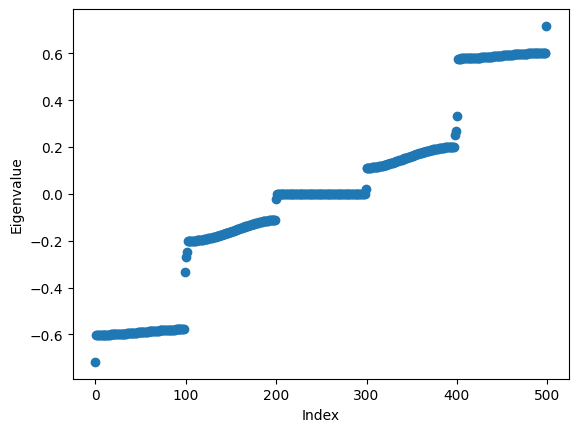

In [ ]:
#initialize matricies with given values (and find eigenvalues/states)

#model 1
H1 = hamiltonian(N1, M1, tA1, tB1)
#eigenvalues1, eigenstates1 = np.linalg.eigh(H1)

#model 2
H2 = hamiltonian(N2, M2, tA2, tB2)
#eigenvalues2, eigenstates2 = np.linalg.eigh(H2)

#combine model
n_interface = 2; #number of connections
H = combined(H1, H2, n_interface)
eigenvalues, eigenstates = np.linalg.eigh(H)

#print eigenvalues (and eigenstates) of combined model
#print ("Eigenvalues:")
#print (eigenvalues)
#print ("Eigenstates:")
#print (eigenstates)

#plot combined model
plt.plot(eigenvalues, 'o')
plt.xlabel('Index')
plt.ylabel('Eigenvalue')
plt.show()

Energy for eigenstate 100: -0.26945126915080714


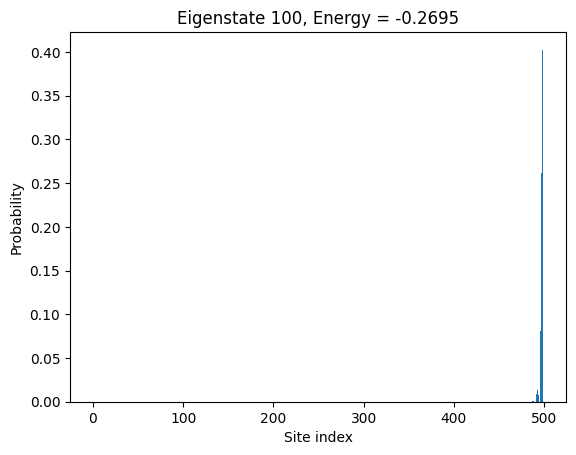

In [ ]:
n = 100 #site index
eigenstate_n = eigenstates[:, n]
prob = np.abs(eigenstate_n)**2

print(f"Energy for eigenstate {n}: {eigenvalues[n]}")
#print(f"Eigenstate {n}: {eigenstate_n}")

plt.figure()
plt.bar(np.arange(len(prob)), prob)
plt.xlabel('Site index')
plt.ylabel('Probability')
plt.title(f"Eigenstate {n}, Energy = {eigenvalues[n]: 0.4f}")
plt.show()

In [ ]:
#print amplitudes with indices
for i, a in enumerate(eigenstate_n):
  print(f"Index {i}: Amplitude = {a}")

Index 0: Amplitude = (-5.3153294204515585e-05+0j)
Index 1: Amplitude = (0.0001537328389995355+0j)
Index 2: Amplitude = (-0.0005219748757120146+0j)
Index 3: Amplitude = (0.0018591792041909203+0j)
Index 4: Amplitude = (-0.000642813206744854+0j)
Index 5: Amplitude = (-0.001737169807630317+0j)
Index 6: Amplitude = (0.0003763886811250447+0j)
Index 7: Amplitude = (0.0008647440794893506+0j)
Index 8: Amplitude = (-0.0037111349550858147+0j)
Index 9: Amplitude = (0.0012831288967540223+0j)
Index 10: Amplitude = (0.0035207434982495135+0j)
Index 11: Amplitude = (-0.000905047821478395+0j)
Index 12: Amplitude = (-0.001204153500381382+0j)
Index 13: Amplitude = (0.005548671864611246+0j)
Index 14: Amplitude = (-0.001918459256872847+0j)
Index 15: Amplitude = (-0.005290638073822166+0j)
Index 16: Amplitude = (0.001430190587157308+0j)
Index 17: Amplitude = (0.001538884433824803+0j)
Index 18: Amplitude = (-0.0073646505660956525+0j)
Index 19: Amplitude = (0.0025463358434063632+0j)
Index 20: Amplitude = (0.007

In [ ]:
#print max amplitude
print("Max amplitude:", np.max(np.abs(eigenstate_n)))

#print max probability
max_prob = np.argmax(np.abs(eigenstate_n)**2)
print(f"Max probability = {abs(eigenstate_n[max_prob])**2} at index {max_prob}")

Max amplitude: 0.13213478236635104
Max probability = 0.017459600711002953 at index 373


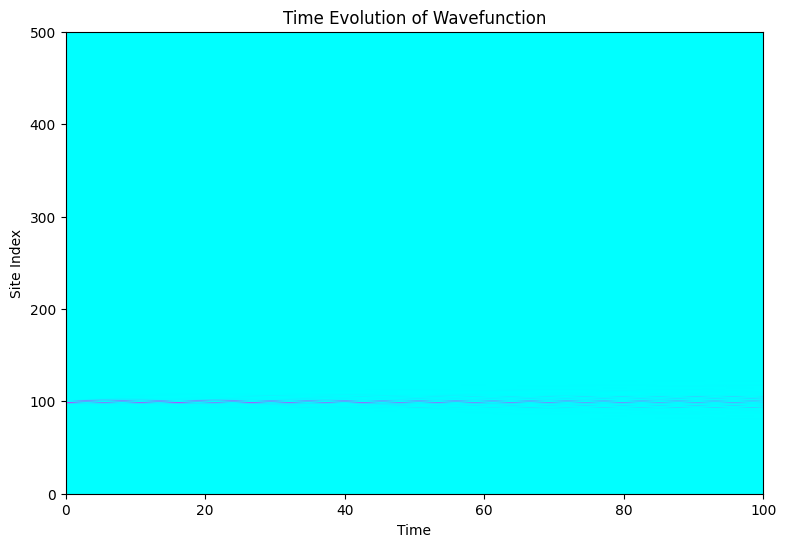

In [ ]:
h_bar = 1 #reduced planck constant (1 because natural units)

psi0 = np.zeros(H.shape[0], dtype=complex) #initialize psi0
psi0[n] = 1.0

coefficients = np.dot(np.conj(eigenstates.T), psi0) #project psi onto eigenbasis

#define time points
tmax = 100 #max simulation time
nt = 400 #number of time samples between 0 and max
times = np.linspace(0, tmax, nt) # generate array of nt evenly spaced values

#prob at each site and time
prob_t = np.zeros((H.shape[0], nt)) #2D (sites, time) array with zeroes
for j, t in enumerate(times): #loop over each time val t and its index j
  #compute time evolution phase
  phase = np.exp(-1j * eigenvalues * t/h_bar)
  #reconstruct full state at time t
  psi_t = np.dot(eigenstates, phase * coefficients)
  #compute probability at each site
  prob_t[:, j] = np.abs(psi_t)**2

#create map for time evolution
plt.figure(figsize = (9, 6))
plt.imshow(prob_t, aspect = "auto", origin = "lower", extent = [times[0], times[-1], 0, H.shape[0]], cmap = "cool")
plt.xlabel("Time")
plt.ylabel("Site Index")
plt.title("Time Evolution of Wavefunction")
plt.show()


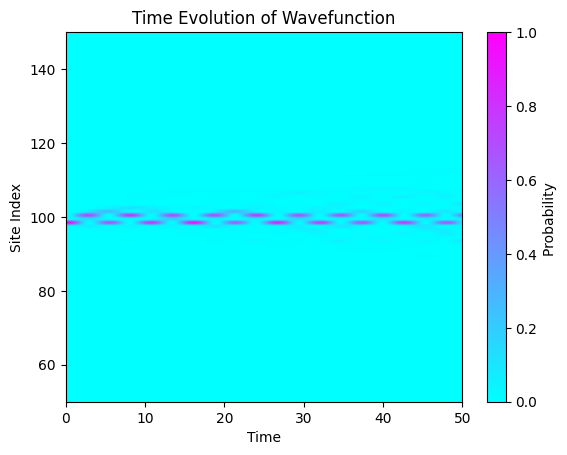

In [ ]:
#zoomed in
plt.imshow(prob_t, aspect = "auto", origin = "lower", extent = [times[0], times[-1], 0, H.shape[0]], cmap = "cool")
plt.xlim(0,50)
plt.ylim(50, 150)
plt.colorbar(label = "Probability ")
plt.xlabel("Time")
plt.ylabel("Site Index")
plt.title("Time Evolution of Wavefunction")
plt.show()

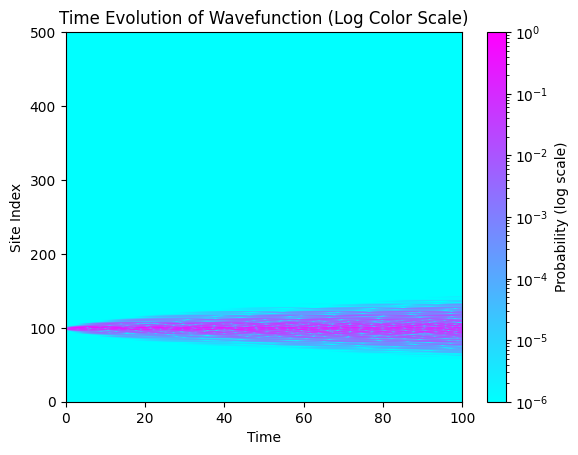

In [ ]:
#log scale
plt.imshow(prob_t, aspect = "auto", origin = "lower", extent = [times[0], times[-1], 0, H.shape[0]], cmap = "cool",
           norm = colors.LogNorm(vmin = 1e-6, vmax = np.max(prob_t)))
plt.colorbar(label = "Probability (log scale)")
plt.xlabel("Time")
plt.ylabel("Site Index")
plt.title("Time Evolution of Wavefunction (Log Color Scale)")
plt.show()